# Tutorial: Máquinas de Vectores de Soporte (SVM) con Python y scikit-learn

**Técnica:** SVM (*Support Vector Machine*) para clasificación, con kernel lineal y kernel RBF.

**Contenido**
1. Fundamentos teóricos de la SVM
2. Modelo matemático (sin desarrollo analítico)
3. Contraste: SVM vs. Perceptrón
4. Pipeline de Machine Learning, etapa por etapa
   - 4.1 Recolección de datos (importar un CSV)
   - 4.2 Descripción y análisis del dataset
   - 4.3 Scatter plot
   - 4.4 Preparación de los datos
   - 4.5 Entrenamiento de una SVM lineal
   - 4.6 Selección de hiperparámetros (`GridSearchCV`)
   - 4.7 Evaluación (métricas)
   - 4.8 Visualización: frontera, margen y vectores de soporte
   - 4.9 Efecto del hiperparámetro C
   - 4.10 Predicción con datos nuevos
   - 4.11 Contraste experimental: SVM vs. Perceptrón
5. Conclusiones

> Cómo usarlo: ejecuta las celdas **en orden**, de arriba hacia abajo. Funciona igual en Google Colab y en Jupyter.

## 1. Fundamentos teóricos de la SVM

### 1.1 Origen y objetivo
La SVM fue desarrollada por **Vladimir Vapnik** y colaboradores (la versión con margen suave y kernels se consolidó en los años 90). Es un algoritmo de **aprendizaje supervisado** que sirve para **clasificación** (`SVC` en scikit-learn), **regresión** (`SVR`) y detección de anomalías. En este tutorial usamos clasificación binaria.

### 1.2 La idea central: el margen máximo
Cuando dos clases se pueden separar con una recta (o un plano, o un hiperplano), normalmente existen **infinitas** rectas que lo logran. La pregunta es cuál elegir.

La SVM elige la que deja **la mayor distancia posible** entre la frontera y los puntos más cercanos de cada clase. Esa distancia se llama **margen**. Un margen grande da más "holgura" y, en general, **generaliza mejor** ante datos nuevos.

### 1.3 Vectores de soporte
Los **vectores de soporte** son los puntos que quedan **sobre el margen o dentro de él**. Son los únicos que determinan la frontera: si borras cualquier otro punto, la frontera no cambia. De ahí viene el nombre de la técnica.

### 1.4 Margen duro y margen suave
- **Margen duro (*hard margin*):** exige que ningún punto quede dentro del margen ni del lado equivocado. Solo funciona si las clases son perfectamente separables y es muy sensible a datos atípicos.
- **Margen suave (*soft margin*):** **tolera** algunos puntos dentro del margen o mal clasificados, a cambio de una penalización. Es lo que se usa en la práctica, y se controla con el hiperparámetro **C**.

| Valor de C | Efecto |
|---|---|
| **C pequeño** | Margen ancho, tolera más errores (modelo más simple, riesgo de subajuste) |
| **C grande** | Margen estrecho, tolera pocos errores (modelo más complejo, riesgo de sobreajuste) |

### 1.5 El truco del kernel (*kernel trick*)
Si las clases **no** se pueden separar con una recta, la SVM puede aplicar un **kernel**: una función que permite comportarse como si los datos se hubieran llevado a un espacio de más dimensiones, donde sí podrían separarse con un hiperplano. La frontera en el espacio original resulta **curva**. Los kernels más comunes son:
- **Lineal:** frontera recta.
- **Polinomial:** fronteras curvas de cierto grado.
- **RBF (gaussiano):** fronteras flexibles, el más usado por defecto.

### 1.6 Hiperparámetros principales
- **C:** qué tanto se penalizan los errores (ver tabla anterior).
- **kernel:** tipo de frontera (`linear`, `poly`, `rbf`).
- **gamma** (en RBF): qué tan "local" es la influencia de cada punto. Gamma grande hace fronteras muy ajustadas (sobreajuste); gamma pequeño las hace suaves.

### 1.7 Buenas prácticas y limitaciones
- **Siempre se deben escalar las características**, porque la SVM se basa en distancias.
- Funciona muy bien con **pocos o medianos volúmenes de datos** y con muchas características.
- Con **datasets muy grandes** el entrenamiento se vuelve lento.
- Por defecto entrega **clases**, no probabilidades (se pueden estimar con `probability=True`, pero es más costoso).
- Para varias clases, scikit-learn combina varias SVM binarias (estrategia uno-contra-uno).

## 2. Modelo matemático

> **Nota:** en esta sección se **presenta** el modelo y se explica qué significa cada elemento. **No se desarrolla** la solución analítica (no hay derivación con multiplicadores de Lagrange ni problema dual).

### 2.1 Función de decisión (caso lineal)
Con entradas $\mathbf{x}$, un vector de pesos $\mathbf{w}$ y un sesgo $b$:

$$f(\mathbf{x}) = \mathbf{w}^{T}\mathbf{x} + b$$

La clase se decide por el signo, con etiquetas $y\in\{-1,+1\}$:

$$\hat{y} = \begin{cases} +1 & \text{si } f(\mathbf{x}) \ge 0 \\ -1 & \text{si } f(\mathbf{x}) < 0 \end{cases}$$

- La **frontera de decisión** es $f(\mathbf{x})=0$.
- Las dos rectas del **margen** son $f(\mathbf{x})=+1$ y $f(\mathbf{x})=-1$.
- El **ancho del margen** es:

$$\text{margen} = \frac{2}{\lVert \mathbf{w} \rVert}$$

Por lo tanto, **maximizar el margen equivale a minimizar $\lVert\mathbf{w}\rVert$**. Ejemplo: si $\mathbf{w}=(1,1)$, entonces $\lVert\mathbf{w}\rVert=\sqrt{2}$ y el margen mide $2/\sqrt{2}\approx 1.41$ unidades.

### 2.2 Problema de optimización (margen suave)
La SVM busca los valores de $\mathbf{w}$ y $b$ que resuelven:

$$\min_{\mathbf{w},\,b,\,\xi}\;\; \frac{1}{2}\lVert\mathbf{w}\rVert^{2} + C\sum_{i=1}^{m}\xi_i
\qquad \text{sujeto a} \qquad y_i\,(\mathbf{w}^{T}\mathbf{x}_i + b) \ge 1-\xi_i,\;\; \xi_i \ge 0$$

Cómo leerlo:
- $\frac{1}{2}\lVert\mathbf{w}\rVert^{2}$: premia un **margen ancho**.
- $\xi_i$ (*variables de holgura*): cuánto se "equivoca" el ejemplo $i$. Vale 0 si está del lado correcto y fuera del margen.
- $C$: peso de la penalización por errores. Es el **balance** entre margen ancho y pocos errores.
- La restricción pide que cada punto quede del lado correcto con al menos margen 1, salvo la holgura permitida.

### 2.3 Forma equivalente con la pérdida *hinge*
El mismo problema se puede escribir como una función de pérdida:

$$J(\mathbf{w},b) = \frac{1}{2}\lVert\mathbf{w}\rVert^{2} + C\sum_{i=1}^{m}\max\!\big(0,\;1-y_i\,f(\mathbf{x}_i)\big)$$

La pérdida *hinge* $\max(0,\,1-y\,f)$ vale 0 si el punto está bien clasificado y fuera del margen, y crece linealmente cuanto más se adentra en el lado equivocado.

### 2.4 Función de decisión con kernel
Cuando se usa un kernel, la función de decisión toma la forma:

$$f(\mathbf{x}) = \sum_{i \in SV} \alpha_i\, y_i\, K(\mathbf{x}_i,\mathbf{x}) + b$$

- La suma incluye **solo los vectores de soporte** (SV).
- $\alpha_i$ son coeficientes que el algoritmo calcula (distintos de cero solo para los vectores de soporte).
- $K(\mathbf{x}_i,\mathbf{x})$ es el **kernel**: una medida de similitud entre dos puntos.

### 2.5 Kernels más comunes

| Kernel | Fórmula $K(\mathbf{x},\mathbf{z})$ | Parámetros |
|---|---|---|
| Lineal | $\mathbf{x}^{T}\mathbf{z}$ | ninguno |
| Polinomial | $(\gamma\,\mathbf{x}^{T}\mathbf{z} + r)^{d}$ | $\gamma$, $r$, grado $d$ |
| RBF (gaussiano) | $\exp\!\big(-\gamma\,\lVert\mathbf{x}-\mathbf{z}\rVert^{2}\big)$ | $\gamma$ |

En el kernel RBF, $\gamma$ controla el alcance: con $\gamma$ grande, solo los puntos muy cercanos se consideran "similares" y la frontera se vuelve muy irregular.

## 3. Contraste: SVM vs. Perceptrón

Ambos son **clasificadores lineales** que buscan un hiperplano $\mathbf{w}^T\mathbf{x}+b=0$, pero difieren en **qué hiperplano eligen** y en qué tan flexibles son.

| Aspecto | Perceptrón | SVM |
|---|---|---|
| **Qué hiperplano elige** | **Cualquiera** que separe las clases | El de **margen máximo** |
| **Unicidad de la solución** | No es única: depende del orden de los datos y de la inicialización | **Única** (el problema de optimización es convexo) |
| **Cómo aprende** | Corrige solo cuando se equivoca, de forma iterativa | Resuelve un problema de optimización global |
| **Qué puntos influyen** | Los que provocaron correcciones | Solo los **vectores de soporte** |
| **Datos no separables** | **No converge**; oscila | **Margen suave** (C) tolera errores |
| **Fronteras no lineales** | **No puede** (solo rectas) | **Sí**, con kernels |
| **Función de pérdida** | $\max(0,\,-y\,f)$, sin regularización | $\max(0,\,1-y\,f)$ más el término $\frac{1}{2}\lVert\mathbf{w}\rVert^2$ |
| **Generalización** | Sin garantía de margen | Margen amplio, normalmente mejor generalización |
| **Costo computacional** | Muy bajo y rápido | Mayor, sobre todo con muchos datos |
| **Salida** | Solo la clase | Clase + **distancia con signo** a la frontera (`decision_function`) |
| **Hiperparámetros** | `eta0`, `max_iter` | `C`, `kernel`, `gamma` |

**Resumen:** el Perceptrón se conforma con *cualquier* recta que funcione; la SVM busca la recta **más segura**. La pérdida *hinge* de la SVM es parecida a la del Perceptrón, pero exige además un **margen de seguridad** (el "1") y **penaliza pesos grandes** (el término $\frac{1}{2}\lVert\mathbf{w}\rVert^2$).

En la **sección 4.11** revisamos con código cuáles de estas diferencias se notan en la práctica y cuáles no, usando los mismos datos del tutorial del Perceptrón.

## 4. Pipeline de Machine Learning

### 4.0 Importación de librerías

In [1]:
import os  # Módulo del sistema operativo: para revisar si existe un archivo
import numpy as np  # NumPy: arreglos numéricos y operaciones vectoriales
import pandas as pd  # Pandas: tablas (DataFrame) para leer y analizar los datos
import matplotlib.pyplot as plt  # Matplotlib: gráficas (scatter plot, fronteras, márgenes)
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV  # Dividir datos, validación cruzada y búsqueda de hiperparámetros
from sklearn.preprocessing import StandardScaler  # Estandariza las variables (media 0, desviación 1)
from sklearn.pipeline import make_pipeline  # Encadena el escalado y el modelo en un solo objeto
from sklearn.svm import SVC  # Clasificador SVM de scikit-learn (Support Vector Classifier)
from sklearn.linear_model import Perceptron  # Perceptrón, para el contraste con la SVM
from sklearn.datasets import make_moons  # Generador de datos "lunas" (no lineales) para el contraste
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # Métricas de clasificación
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay  # Matriz y reporte

np.random.seed(42)  # Fija la semilla para que los resultados sean reproducibles
plt.rcParams["figure.figsize"] = (8, 5)  # Tamaño por defecto de las figuras
plt.rcParams["axes.grid"] = True  # Activa la cuadrícula en todas las gráficas

### 4.1 Etapa 1: Recolección de datos (importar un CSV)

Usamos el dataset **Iris** (el mismo del tutorial del Perceptrón): 150 flores de tres especies con 4 medidas en centímetros. Los datos se **importan desde un CSV** con `pd.read_csv`.

> **Para Google Colab:** sube el archivo `iris.csv` con el ícono de carpeta (panel izquierdo). Si no lo subes, la celda siguiente **crea el CSV automáticamente** desde scikit-learn, así que el notebook funciona de cualquier forma.

In [2]:
RUTA_CSV = "iris.csv"  # Nombre del archivo CSV que vamos a leer

if not os.path.exists(RUTA_CSV):  # Si el archivo todavía no existe en la carpeta de trabajo...
    from sklearn.datasets import load_iris  # ...importamos el cargador de Iris de scikit-learn
    iris = load_iris(as_frame=True)  # Carga Iris como un DataFrame de Pandas
    tabla = iris.frame.copy()  # Copia la tabla completa (características + objetivo numérico)
    tabla.columns = ["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo", "especie"]  # Nombres de columnas
    tabla["especie"] = tabla["especie"].map({0: "setosa", 1: "versicolor", 2: "virginica"})  # Cambia números por nombres
    tabla.to_csv(RUTA_CSV, index=False)  # Guarda la tabla como archivo CSV (sin la columna de índice)
    print("No se encontró el CSV; se creó:", RUTA_CSV)  # Avisa que el archivo se generó
else:  # Si el archivo ya existía...
    print("CSV encontrado:", RUTA_CSV)  # ...avisa que se usará ese archivo

datos = pd.read_csv(RUTA_CSV)  # LEE el CSV y lo carga en un DataFrame llamado "datos"
datos.head()  # Muestra las primeras 5 filas para confirmar que se leyó bien

CSV encontrado: iris.csv


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 4.2 Etapa 2: Descripción y análisis del dataset

Revisamos tamaño, tipos de datos, valores faltantes, balance de clases, rangos y relaciones entre variables.

In [3]:
print("Dimensiones (filas, columnas):", datos.shape)  # Cuántas observaciones y variables hay
print("\nTipos de datos y valores no nulos:")  # Título con salto de línea previo
datos.info()  # Tipo de cada columna y cantidad de valores no nulos

Dimensiones (filas, columnas): (150, 5)

Tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   largo_sepalo  150 non-null    float64
 1   ancho_sepalo  150 non-null    float64
 2   largo_petalo  150 non-null    float64
 3   ancho_petalo  150 non-null    float64
 4   especie       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
print("Valores faltantes por columna:")  # Título de la revisión de datos faltantes
print(datos.isnull().sum())  # Cuenta los nulos de cada columna (esperamos 0)
print("\nObservaciones por especie (balance de clases):")  # Título del conteo por clase
print(datos["especie"].value_counts())  # Cuántas flores hay de cada especie
print("\nEstadísticos descriptivos:")  # Título de la tabla de estadísticos
datos.describe().round(3)  # Media, desviación, mínimo, cuartiles y máximo de cada medida

Valores faltantes por columna:
largo_sepalo    0
ancho_sepalo    0
largo_petalo    0
ancho_petalo    0
especie         0
dtype: int64

Observaciones por especie (balance de clases):
especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Estadísticos descriptivos:


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


In [5]:
print("Media de cada medida por especie:")  # Título de la tabla comparativa
display(datos.groupby("especie").mean().round(3))  # Promedio de cada medida separado por especie
print("Correlación entre las medidas:")  # Título de la matriz de correlación
datos.drop(columns="especie").corr().round(3)  # Correlación de Pearson entre las 4 medidas numéricas

Media de cada medida por especie:


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
especie,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


Correlación entre las medidas:


,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo
largo_sepalo,1.000,-0.118,0.872,0.818
ancho_sepalo,-0.118,1.000,-0.428,-0.366
largo_petalo,0.872,-0.428,1.000,0.963
ancho_petalo,0.818,-0.366,0.963,1.000


**Interpretación.**
- No hay valores faltantes y las 4 medidas son numéricas continuas.
- Las clases están **balanceadas** (50 flores por especie).
- Las medidas del **pétalo** están muy correlacionadas entre sí y distinguen bien a las especies. Entre *versicolor* y *virginica* los promedios son cercanos, así que esperamos cierto traslape.

### 4.3 Etapa 3: Scatter plot (diagrama de dispersión)

Graficamos el largo contra el ancho del pétalo, con un color por especie, para ver qué tan separables son las clases.

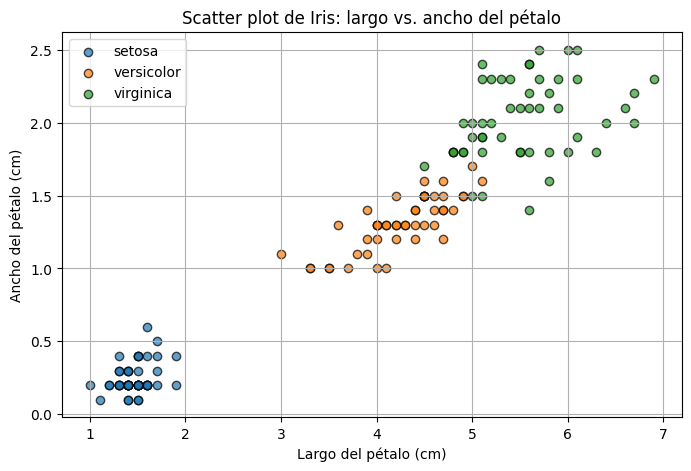

In [6]:
fig, ax = plt.subplots()  # Crea la figura (fig) y el área de dibujo (ax)
colores = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}  # Un color por especie
for especie, grupo in datos.groupby("especie"):  # Recorre cada especie con su subtabla
    ax.scatter(grupo["largo_petalo"], grupo["ancho_petalo"], label=especie, color=colores[especie], alpha=0.7, edgecolor="k")  # Dibuja los puntos
ax.set_xlabel("Largo del pétalo (cm)")  # Etiqueta del eje horizontal
ax.set_ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje vertical
ax.set_title("Scatter plot de Iris: largo vs. ancho del pétalo")  # Título de la gráfica
ax.legend()  # Muestra la leyenda con las especies
plt.show()  # Muestra la gráfica en el notebook

**Interpretación.** *Setosa* (azul) queda totalmente separada. *Versicolor* (naranja) y *virginica* (verde) se acercan y se **traslapan un poco** en la zona intermedia. Ese es el caso interesante: no existe una recta que las separe sin ningún error, y justo ahí el margen suave de la SVM marca la diferencia. Trabajaremos con estas dos especies.

### 4.4 Etapa 4: Preparación de los datos

Pasos de esta etapa:
1. **Seleccionar** *versicolor* y *virginica* (problema binario).
2. **Codificar** la especie: *versicolor* = 0 y *virginica* = 1.
3. **Separar** en entrenamiento (80 %) y prueba (20 %), manteniendo la proporción de clases.
4. **Escalar** las características. Esto se hará dentro del `Pipeline`, así el escalador se ajusta **solo con los datos de entrenamiento** (sin filtrar información de la prueba).

In [7]:
CARACTERISTICAS = ["largo_petalo", "ancho_petalo"]  # Las dos variables de entrada (X) que usaremos
binario = datos[datos["especie"].isin(["versicolor", "virginica"])].copy()  # Se queda solo con las dos especies elegidas
X = binario[CARACTERISTICAS].values  # Matriz de entradas (100 filas x 2 columnas) como arreglo NumPy
y = (binario["especie"] == "virginica").astype(int).values  # Etiqueta: 1 si es virginica, 0 si es versicolor
NOMBRES = ("versicolor", "virginica")  # Nombres de las clases 0 y 1 para las gráficas

print("Forma de X:", X.shape)  # Confirma el tamaño de la matriz de entradas
print("Clases en y (0 = versicolor, 1 = virginica):", np.bincount(y))  # Cuenta cuántas hay de cada clase

Forma de X: (100, 2)
Clases en y (0 = versicolor, 1 = virginica): [50 50]


In [8]:
X_train, X_test, y_train, y_test = train_test_split(  # Divide los datos en entrenamiento y prueba
    X, y,  # Entradas y etiquetas que se van a dividir
    test_size=0.2,  # 20 % de las observaciones se reservan para prueba
    random_state=42,  # Semilla para que la división sea siempre la misma
    stratify=y  # Mantiene la misma proporción de clases en ambos conjuntos
)  # Cierra la llamada a train_test_split

print("Observaciones de entrenamiento:", X_train.shape[0])  # Cuántas filas quedaron para entrenar
print("Observaciones de prueba:", X_test.shape[0])  # Cuántas filas quedaron para probar
print("Clases en entrenamiento:", np.bincount(y_train))  # Balance de clases en entrenamiento
print("Clases en prueba:", np.bincount(y_test))  # Balance de clases en prueba

Observaciones de entrenamiento: 80
Observaciones de prueba: 20
Clases en entrenamiento: [40 40]
Clases en prueba: [10 10]


### 4.5 Etapa 5: Entrenamiento de una SVM lineal

Primero entrenamos un modelo base con kernel **lineal** y `C=1.0`. El `Pipeline` encadena:
1. `StandardScaler()`: estandariza las características.
2. `SVC(kernel="linear", C=1.0)`: busca la frontera de margen máximo.

In [9]:
svm_lineal = make_pipeline(  # Crea el pipeline de la SVM lineal
    StandardScaler(),  # Paso 1: estandariza cada característica (media 0, desviación 1)
    SVC(kernel="linear", C=1.0)  # Paso 2: SVM con kernel lineal y penalización C = 1
)  # Cierra la creación del pipeline

svm_lineal.fit(X_train, y_train)  # Entrena: ajusta el escalador y luego resuelve el problema de optimización de la SVM

svc = svm_lineal.named_steps["svc"]  # Extrae la SVM ya entrenada del pipeline
print("Pesos w (en escala estandarizada):", svc.coef_[0])  # Vector w de la frontera (solo existe con kernel lineal)
print("Sesgo b:", svc.intercept_[0])  # Sesgo de la frontera
print("Ancho del margen 2/||w||:", 2 / np.linalg.norm(svc.coef_[0]))  # Aplica la fórmula del margen de la sección 2.1
print("Vectores de soporte por clase:", svc.n_support_)  # Cuántos vectores de soporte aportó cada clase
print("Total de vectores de soporte:", svc.n_support_.sum(), "de", len(X_train), "datos de entrenamiento")  # Total sobre el tamaño de entrenamiento

Pesos w (en escala estandarizada): [1.19199769 1.71306765]
Sesgo b: 0.14130617613124932
Ancho del margen 2/||w||: 0.9583254407990516
Vectores de soporte por clase: [6 7]
Total de vectores de soporte: 13 de 80 datos de entrenamiento


**Interpretación.** El modelo guarda un vector de pesos $\mathbf{w}$ y un sesgo $b$ que definen la frontera. Lo más importante: **solo una parte de los datos de entrenamiento son vectores de soporte**; el resto no influye en la frontera. Con datos traslapados, hay vectores de soporte de ambas clases (los puntos dentro del margen o mal clasificados).

### 4.6 Etapa 6: Selección de hiperparámetros (`GridSearchCV`)

En lugar de elegir `kernel`, `C` y `gamma` "a ojo", probamos varias combinaciones y nos quedamos con la mejor según la **validación cruzada de 5 pliegues** sobre los datos de entrenamiento. Los datos de prueba **no se tocan** hasta la evaluación final.

- `kernel`: `linear` o `rbf`.
- `C`: 0.1, 1, 10, 100.
- `gamma` (solo afecta a `rbf`): `"scale"` (valor automático), 0.1 y 1.

In [10]:
pipe_base = make_pipeline(StandardScaler(), SVC())  # Pipeline base: escalador + SVM (sin hiperparámetros fijos)

rejilla = {  # Diccionario con las combinaciones de hiperparámetros a probar
    "svc__kernel": ["linear", "rbf"],  # Tipos de kernel a probar (svc__ indica el paso "svc" del pipeline)
    "svc__C": [0.1, 1, 10, 100],  # Valores de la penalización C
    "svc__gamma": ["scale", 0.1, 1.0]  # Valores de gamma (los usa el kernel rbf)
}  # Cierra el diccionario

busqueda = GridSearchCV(  # Crea el buscador de hiperparámetros
    pipe_base,  # Modelo sobre el que se prueban las combinaciones
    rejilla,  # Combinaciones a probar
    cv=5,  # Validación cruzada de 5 pliegues
    scoring="accuracy"  # Métrica para decidir cuál combinación es mejor
)  # Cierra la creación del buscador

busqueda.fit(X_train, y_train)  # Prueba todas las combinaciones y reajusta la mejor con todo el entrenamiento

print("Mejores hiperparámetros:", busqueda.best_params_)  # Combinación ganadora
print(f"Mejor exactitud en validación cruzada: {busqueda.best_score_:.4f}")  # Exactitud promedio de la combinación ganadora

Mejores hiperparámetros: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Mejor exactitud en validación cruzada: 0.9875


In [11]:
resultados = pd.DataFrame(busqueda.cv_results_)  # Convierte todos los resultados de la búsqueda en una tabla
columnas = ["param_svc__kernel", "param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score", "rank_test_score"]  # Columnas que nos interesan
resultados[columnas].sort_values("rank_test_score").head(8).round(4)  # Muestra las 8 mejores combinaciones ordenadas por ranking

,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,std_test_score,rank_test_score
0,linear,0.1,scale,0.9875,0.0250,1
2,linear,0.1,0.1,0.9875,0.0250,1
4,linear,0.1,1.0,0.9875,0.0250,1
1,rbf,0.1,scale,0.9750,0.0306,4
3,rbf,0.1,0.1,0.9750,0.0306,4
17,rbf,10.0,1.0,0.9750,0.0306,4
23,rbf,100.0,1.0,0.9750,0.0306,4
6,linear,1.0,scale,0.9625,0.0306,8


**Interpretación.** La tabla muestra las combinaciones ordenadas de mejor a peor (`rank_test_score`). Ganó el **kernel lineal con C = 0.1** (exactitud en validación cruzada de 0.9875). Los tres primeros renglones son en realidad **el mismo modelo**: `gamma` no afecta al kernel lineal, por eso el puntaje se repite. El kernel RBF quedó muy cerca (0.975); esa diferencia es menor que la desviación entre pliegues (`std_test_score`, entre 0.025 y 0.031), así que no es un resultado concluyente. Para estos datos, que son casi separables con una recta, un modelo lineal simple es suficiente. El modelo ganador ya quedó reajustado con todo el conjunto de entrenamiento y está en `busqueda.best_estimator_`.

### 4.7 Etapa 7: Evaluación del modelo (métricas)

Evaluamos con los **datos de prueba** (que el modelo nunca vio). Llamamos "positivo" a la clase 1 (*virginica*). Las métricas son las mismas del tutorial del Perceptrón:

| Métrica | Fórmula | Qué indica |
|---|---|---|
| Exactitud (*accuracy*) | $\frac{VP+VN}{VP+VN+FP+FN}$ | Proporción total de aciertos |
| Precisión | $\frac{VP}{VP+FP}$ | De los que predije como 1, cuántos lo eran |
| Recall (sensibilidad) | $\frac{VP}{VP+FN}$ | De los que realmente eran 1, cuántos detecté |
| F1 | $2\cdot\frac{Precisión\cdot Recall}{Precisión+Recall}$ | Balance entre precisión y recall |

In [12]:
modelo_final = busqueda.best_estimator_  # El mejor pipeline encontrado por GridSearchCV, ya entrenado

def calcular_metricas(y_real, y_est):  # Función que devuelve las métricas principales de un conjunto
    return {  # Devuelve un diccionario con las métricas
        "Exactitud": accuracy_score(y_real, y_est),  # Proporción de aciertos
        "Precisión": precision_score(y_real, y_est),  # Precisión de la clase positiva
        "Recall": recall_score(y_real, y_est),  # Sensibilidad de la clase positiva
        "F1": f1_score(y_real, y_est)  # Media armónica de precisión y recall
    }  # Cierra el diccionario

y_pred_train = modelo_final.predict(X_train)  # Predicciones sobre los datos de entrenamiento
y_pred_test = modelo_final.predict(X_test)  # Predicciones sobre los datos de prueba (nunca vistos)

metricas = pd.DataFrame({  # Tabla comparando entrenamiento y prueba
    "Entrenamiento": calcular_metricas(y_train, y_pred_train),  # Métricas con los datos de entrenamiento
    "Prueba": calcular_metricas(y_test, y_pred_test)  # Métricas con los datos de prueba
})  # Cierra la creación de la tabla
metricas.round(4)  # Muestra la tabla con 4 decimales

,Entrenamiento,Prueba
Exactitud,0.9625,0.8500
Precisión,0.9512,0.8889
Recall,0.9750,0.8000
F1,0.9630,0.8421


Matriz de confusión (filas = real, columnas = predicho):
 [[9 1]
 [2 8]]


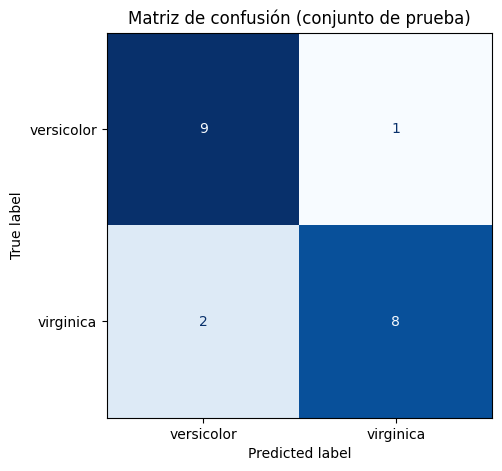

In [13]:
cm = confusion_matrix(y_test, y_pred_test)  # Calcula la matriz de confusión con los datos de prueba
print("Matriz de confusión (filas = real, columnas = predicho):\n", cm)  # La imprime en texto

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(NOMBRES))  # Prepara la gráfica de la matriz
disp.plot(cmap="Blues", colorbar=False)  # La dibuja en azules y sin barra de color
plt.title("Matriz de confusión (conjunto de prueba)")  # Título de la gráfica
plt.grid(False)  # Quita la cuadrícula para que se vea limpia
plt.show()  # Muestra la gráfica

In [14]:
print("Reporte de clasificación (prueba):\n")  # Título del reporte
print(classification_report(y_test, y_pred_test, target_names=list(NOMBRES)))  # Precisión, recall y F1 por clase

Reporte de clasificación (prueba):

              precision    recall  f1-score   support

  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20



**Interpretación.** La exactitud baja de 0.96 en entrenamiento a 0.85 en prueba: el modelo comete 3 errores en 20 datos (1 *versicolor* clasificada como *virginica* y 2 *virginica* clasificadas como *versicolor*). Con solo 20 datos de prueba, **un solo error mueve la exactitud 5 puntos**, así que esta cifra es poco estable: la validación cruzada (0.9875 en la sección 4.6, y alrededor de 0.93 al evaluar sobre los 100 datos en la sección 4.11) da una idea más confiable. Lo razonable es esperar una exactitud entre 0.85 y 0.95 con datos nuevos. Los errores caen justo en la zona de traslape que vimos en el scatter plot.

### 4.8 Etapa 8: Visualización: frontera, margen y vectores de soporte

Definimos una función reutilizable que dibuja:
- las **regiones** que el modelo asigna a cada clase,
- la **frontera** $f(\mathbf{x})=0$ (línea continua) y los **márgenes** $f(\mathbf{x})=\pm1$ (líneas punteadas),
- los **vectores de soporte** (puntos con un círculo alrededor).

In [15]:
def graficar_frontera(ax, modelo, X_in, y_in, titulo, nombres=NOMBRES, niveles=(0,), vectores=None):  # Dibuja la frontera de un modelo en un eje dado
    x_min, x_max = X_in[:, 0].min() - 0.5, X_in[:, 0].max() + 0.5  # Rango horizontal de la malla, con un margen
    y_min, y_max = X_in[:, 1].min() - 0.5, X_in[:, 1].max() + 0.5  # Rango vertical de la malla, con un margen
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))  # Malla de 300 x 300 puntos
    malla = np.c_[xx.ravel(), yy.ravel()]  # Convierte la malla en una lista de pares (x, y)
    zz = modelo.predict(malla).reshape(xx.shape)  # Clase predicha en cada punto de la malla
    ff = modelo.decision_function(malla).reshape(xx.shape)  # Valor de f(x) en cada punto de la malla
    ax.contourf(xx, yy, zz, alpha=0.2, cmap="coolwarm")  # Colorea las regiones de decisión
    estilos = ["--", "-", "--"] if len(niveles) == 3 else ["-"]  # Margen punteado y frontera continua (o solo frontera)
    ax.contour(xx, yy, ff, levels=list(niveles), colors="k", linestyles=estilos, linewidths=1.5)  # Dibuja f(x) = -1, 0, +1 (o solo 0)
    ax.scatter(X_in[y_in == 0, 0], X_in[y_in == 0, 1], color="tab:orange", edgecolor="k", label=nombres[0])  # Puntos de la clase 0
    ax.scatter(X_in[y_in == 1, 0], X_in[y_in == 1, 1], color="tab:green", edgecolor="k", label=nombres[1])  # Puntos de la clase 1
    if vectores is not None:  # Si el modelo tiene vectores de soporte...
        ax.scatter(vectores[:, 0], vectores[:, 1], s=170, facecolors="none", edgecolors="k", linewidths=1.6, label="vectores de soporte")  # ...los rodea con un círculo
    ax.set_xlim(x_min, x_max)  # Fija el límite horizontal de la gráfica
    ax.set_ylim(y_min, y_max)  # Fija el límite vertical de la gráfica
    ax.set_title(titulo)  # Pone el título de la gráfica
    ax.legend(loc="upper left", fontsize=8)  # Muestra la leyenda

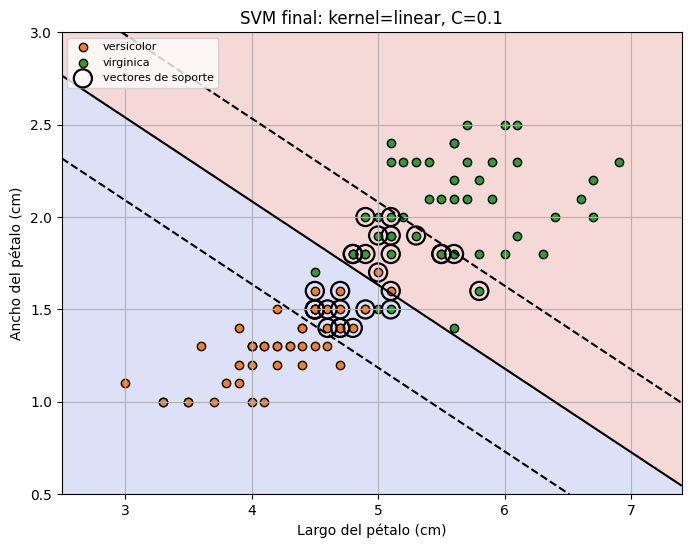

Vectores de soporte del modelo final: 28 de 80


In [16]:
esc_f = modelo_final.named_steps["standardscaler"]  # Escalador del modelo final
svc_f = modelo_final.named_steps["svc"]  # SVM del modelo final
sv_f = esc_f.inverse_transform(svc_f.support_vectors_)  # Devuelve los vectores de soporte a las unidades originales (cm)

fig, ax = plt.subplots(figsize=(8, 6))  # Crea la figura y el área de dibujo
graficar_frontera(ax, modelo_final, X, y, f"SVM final: kernel={svc_f.kernel}, C={svc_f.C}", niveles=(-1, 0, 1), vectores=sv_f)  # Dibuja frontera, márgenes y soporte
ax.set_xlabel("Largo del pétalo (cm)")  # Etiqueta del eje horizontal
ax.set_ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje vertical
plt.show()  # Muestra la gráfica
print("Vectores de soporte del modelo final:", svc_f.n_support_.sum(), "de", len(X_train))  # Cuántos puntos definen la frontera

**Interpretación.** La línea continua es la frontera de decisión y las punteadas son los bordes del margen. Los puntos con círculo son los **vectores de soporte**: los que están sobre el margen, dentro de él o del lado equivocado. Son los únicos que "sostienen" la frontera; el resto de los puntos podría moverse (sin cruzar el margen) y la frontera seguiría igual. Como el modelo ganador usa `C = 0.1`, el margen es ancho y por eso hay bastantes vectores de soporte (28 de 80).

### 4.9 Etapa 9: Efecto del hiperparámetro C

Entrenamos tres SVM lineales con $C=0.01$, $C=1$ y $C=100$, para ver cómo cambia el margen. Es la ilustración práctica de la diferencia entre margen **suave** y margen **casi duro**.

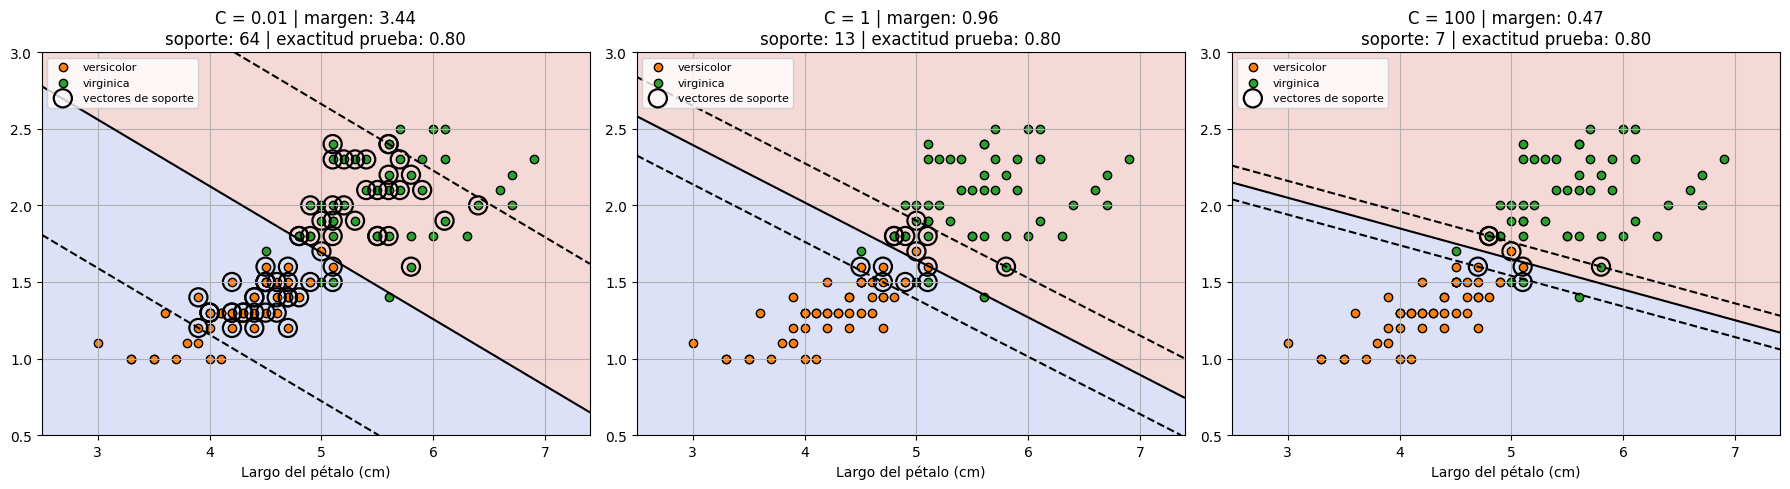

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))  # Crea una figura con 3 gráficas en una fila

for ax, C in zip(ejes, [0.01, 1, 100]):  # Recorre cada eje junto con un valor de C
    m = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))  # Pipeline con SVM lineal y este valor de C
    m.fit(X_train, y_train)  # Entrena el modelo con los datos de entrenamiento
    svc_c = m.named_steps["svc"]  # Extrae la SVM entrenada
    sv_c = m.named_steps["standardscaler"].inverse_transform(svc_c.support_vectors_)  # Vectores de soporte en unidades originales
    acc_c = accuracy_score(y_test, m.predict(X_test))  # Exactitud en prueba de este modelo
    titulo = f"C = {C} | margen: {2 / np.linalg.norm(svc_c.coef_[0]):.2f}\nsoporte: {svc_c.n_support_.sum()} | exactitud prueba: {acc_c:.2f}"  # Título con los datos clave (margen = 2/||w||)
    graficar_frontera(ax, m, X, y, titulo, niveles=(-1, 0, 1), vectores=sv_c)  # Dibuja frontera, margen y soporte
    ax.set_xlabel("Largo del pétalo (cm)")  # Etiqueta del eje horizontal

plt.tight_layout()  # Acomoda las tres gráficas sin que se encimen
plt.show()  # Muestra la figura

**Interpretación.**
- **C pequeño (0.01):** margen muy **ancho** (cerca de 3.4 unidades estandarizadas) y 64 de los 80 puntos son vectores de soporte; el modelo tolera muchos errores.
- **C = 1:** margen intermedio (cerca de 0.96) y 13 vectores de soporte.
- **C grande (100):** margen **estrecho** (cerca de 0.47) y solo 7 vectores de soporte; el modelo se esfuerza más por clasificar bien cada punto de entrenamiento.
- Al subir C, el margen se estrecha y los vectores de soporte disminuyen. En este caso la exactitud de prueba fue 0.80 en los tres modelos: con 20 datos de prueba no se distingue cuál es mejor. El valor ideal se elige con validación cruzada, como hicimos en la sección 4.6.

### 4.10 Etapa 10: Predicción con datos nuevos

Clasificamos flores nuevas. Además de la clase, mostramos `decision_function`, el valor $f(\mathbf{x})$: su **signo** indica la clase y su **magnitud** indica qué tan lejos está la flor de la frontera (un valor de ±1 significa que está justo sobre el margen). Es una ventaja sobre el Perceptrón, que solo entrega la clase.

In [18]:
flores_nuevas = np.array([[4.2, 1.3], [5.8, 2.1], [4.9, 1.6], [5.1, 1.9]])  # 4 flores: [largo_petalo, ancho_petalo] en cm
clases = modelo_final.predict(flores_nuevas)  # El modelo predice 0 (versicolor) o 1 (virginica) para cada flor
valores_f = modelo_final.decision_function(flores_nuevas)  # Valor f(x): signo = clase, magnitud = distancia a la frontera

resultado = pd.DataFrame({  # Tabla con las entradas y las predicciones
    "largo_petalo": flores_nuevas[:, 0],  # Primera característica de cada flor nueva
    "ancho_petalo": flores_nuevas[:, 1],  # Segunda característica de cada flor nueva
    "f(x)": valores_f.round(3),  # Valor de la función de decisión
    "predicción": np.where(clases == 1, NOMBRES[1], NOMBRES[0])  # Nombre de la especie predicha
})  # Cierra la creación de la tabla
resultado  # Muestra la tabla

,largo_petalo,ancho_petalo,f(x),predicción
0,4.2,1.3,-1.551,versicolor
1,5.8,2.1,1.850,virginica
2,4.9,1.6,-0.175,versicolor
3,5.1,1.9,0.697,virginica


**Interpretación.** Las flores con $|f(\mathbf{x})|$ cercano a 0 están **cerca de la frontera**: la predicción es poco segura. Por ejemplo, la flor (4.9, 1.6) tiene un valor cercano a 0 (cae en la zona de traslape), mientras que (4.2, 1.3) y (5.8, 2.1) tienen valores grandes y están claramente dentro de su región.

### 4.11 Etapa 11: Contraste experimental: SVM vs. Perceptrón

Comprobamos con código las diferencias de la sección 3.

#### Experimento A: mismos datos (*versicolor* vs. *virginica*, con traslape)
Comparamos el Perceptrón y la SVM lineal (ambos sin ajuste de hiperparámetros, para que la comparación sea justa), y también el modelo final de la sección 4.6.

In [19]:
perceptron = make_pipeline(StandardScaler(), Perceptron(eta0=1.0, max_iter=1000, random_state=42))  # Perceptrón con el mismo escalado
perceptron.fit(X_train, y_train)  # Entrena el Perceptrón con los mismos datos de entrenamiento

modelos = {  # Diccionario con los tres modelos a comparar
    "Perceptrón": perceptron,  # Perceptrón básico
    "SVM lineal (C=1)": svm_lineal,  # SVM lineal de la sección 4.5
    "SVM final (GridSearch)": modelo_final  # SVM con los mejores hiperparámetros de la sección 4.6
}  # Cierra el diccionario

filas = []  # Lista donde guardaremos una fila de resultados por modelo
for nombre, m in modelos.items():  # Recorre cada modelo con su nombre
    acc_tr = accuracy_score(y_train, m.predict(X_train))  # Exactitud en entrenamiento
    acc_te = accuracy_score(y_test, m.predict(X_test))  # Exactitud en prueba
    filas.append({"Modelo": nombre, "Exactitud train": acc_tr, "Exactitud prueba": acc_te})  # Guarda la fila

pd.DataFrame(filas).round(4)  # Muestra la tabla comparativa con 4 decimales

,Modelo,Exactitud train,Exactitud prueba
0,Perceptrón,0.9750,0.85
1,SVM lineal (C=1),0.9750,0.80
2,SVM final (GridSearch),0.9625,0.85


In [20]:
cv_perceptron = cross_val_score(make_pipeline(StandardScaler(), Perceptron(eta0=1.0, max_iter=1000, random_state=42)), X, y, cv=10)  # Validación cruzada (10 pliegues) del Perceptrón sobre los 100 datos
cv_svm = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0)), X, y, cv=10)  # Validación cruzada (10 pliegues) de la SVM lineal sobre los 100 datos

print(f"Perceptrón   -> exactitud promedio: {cv_perceptron.mean():.4f} | desviación: {cv_perceptron.std():.4f}")  # Resultado del Perceptrón
print(f"SVM lineal   -> exactitud promedio: {cv_svm.mean():.4f} | desviación: {cv_svm.std():.4f}")  # Resultado de la SVM

Perceptrón   -> exactitud promedio: 0.9400 | desviación: 0.0800
SVM lineal   -> exactitud promedio: 0.9300 | desviación: 0.0900


**¿La solución depende del orden de los datos?** El Perceptrón aprende dato por dato, así que su resultado puede cambiar según el orden en que los ve (la semilla controla ese orden). La SVM resuelve un problema de optimización con una sola solución. Lo comprobamos reentrenando varias veces.

In [21]:
filas_p = []  # Lista donde guardaremos los resultados del Perceptrón
for semilla in range(6):  # Prueba 6 semillas distintas (6 órdenes distintos de los datos)
    p_s = make_pipeline(StandardScaler(), Perceptron(eta0=1.0, max_iter=1000, random_state=semilla))  # Perceptrón con esta semilla
    p_s.fit(X_train, y_train)  # Lo entrena con los mismos datos de entrenamiento
    per = p_s.named_steps["perceptron"]  # Extrae el Perceptrón entrenado
    filas_p.append({"semilla": semilla, "w1": per.coef_[0][0], "w2": per.coef_[0][1], "b": per.intercept_[0], "exactitud prueba": accuracy_score(y_test, p_s.predict(X_test))})  # Guarda pesos y exactitud
print("PERCEPTRÓN con distintas semillas:")  # Título de la tabla del Perceptrón
display(pd.DataFrame(filas_p).round(3))  # Muestra la tabla: los pesos cambian de una semilla a otra

filas_s = []  # Lista donde guardaremos los resultados de la SVM
for semilla in range(3):  # Prueba 3 órdenes distintos de los datos de entrenamiento
    orden = np.random.RandomState(semilla).permutation(len(X_train))  # Genera un orden aleatorio de las filas
    s_s = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))  # SVM lineal con C = 1
    s_s.fit(X_train[orden], y_train[orden])  # La entrena con los datos barajados en ese orden
    sv_s = s_s.named_steps["svc"]  # Extrae la SVM entrenada
    filas_s.append({"orden": semilla, "w1": sv_s.coef_[0][0], "w2": sv_s.coef_[0][1], "b": sv_s.intercept_[0], "exactitud prueba": accuracy_score(y_test, s_s.predict(X_test))})  # Guarda pesos y exactitud
print("SVM con los datos en distinto orden:")  # Título de la tabla de la SVM
display(pd.DataFrame(filas_s).round(3))  # Muestra la tabla: los pesos son siempre los mismos

PERCEPTRÓN con distintas semillas:


,semilla,w1,w2,b,exactitud prueba
0,0,2.456,1.594,0.0,0.90
1,1,2.088,1.822,0.0,0.85
2,2,2.211,1.822,0.0,0.85
3,3,1.720,1.594,0.0,0.85
4,4,2.628,2.056,-1.0,0.80
5,5,1.965,1.822,0.0,0.85


SVM con los datos en distinto orden:


,orden,w1,w2,b,exactitud prueba
0,0,1.192,1.713,0.141,0.8
1,1,1.192,1.713,0.141,0.8
2,2,1.192,1.713,0.141,0.8


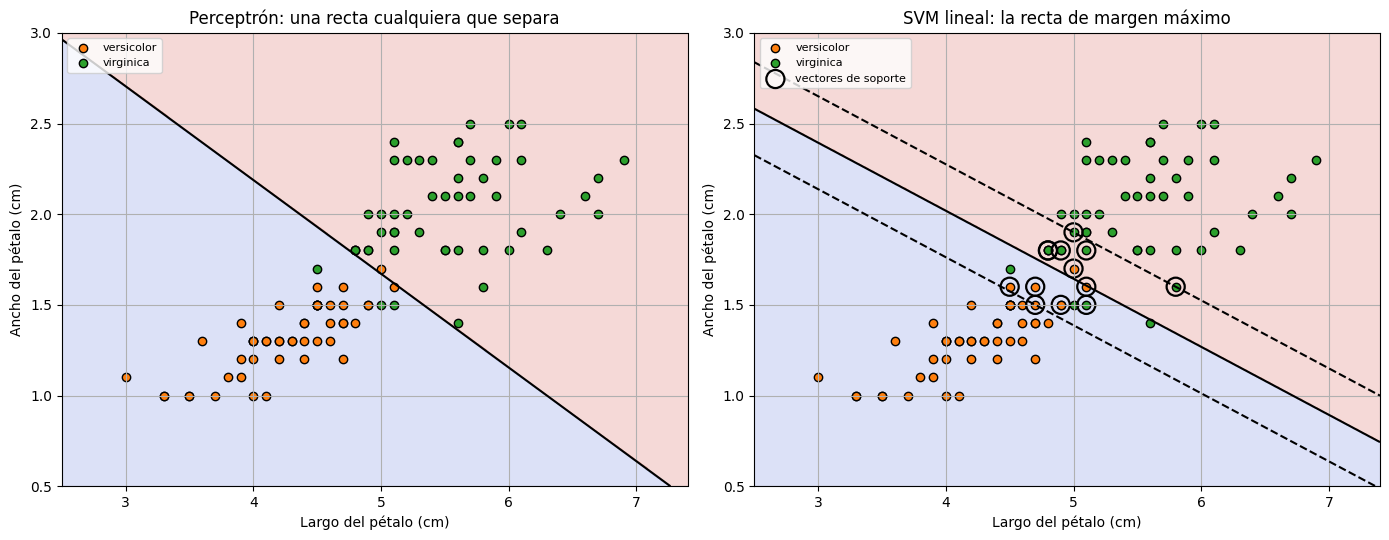

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))  # Crea una figura con 2 gráficas lado a lado

graficar_frontera(ejes[0], perceptron, X, y, "Perceptrón: una recta cualquiera que separa")  # Frontera del Perceptrón (solo f = 0)
sv_l = svm_lineal.named_steps["standardscaler"].inverse_transform(svm_lineal.named_steps["svc"].support_vectors_)  # Vectores de soporte de la SVM lineal
graficar_frontera(ejes[1], svm_lineal, X, y, "SVM lineal: la recta de margen máximo", niveles=(-1, 0, 1), vectores=sv_l)  # Frontera, margen y soporte de la SVM

for ax in ejes:  # Recorre ambos ejes para poner las etiquetas
    ax.set_xlabel("Largo del pétalo (cm)")  # Etiqueta del eje horizontal
    ax.set_ylabel("Ancho del pétalo (cm)")  # Etiqueta del eje vertical

plt.tight_layout()  # Acomoda las gráficas sin que se encimen
plt.show()  # Muestra la figura

**Interpretación del experimento A.**
- **En exactitud no hay un ganador claro** con estos datos. El Perceptrón y la SVM quedan prácticamente empatados (en prueba 0.85 contra 0.80-0.85, y en validación cruzada 0.94 contra 0.93), y esa diferencia es mucho menor que la variación entre pliegues (cerca de 0.08-0.09). Con 100 datos y dos variables, el traslape de las clases limita a ambos por igual: la SVM no puede separar puntos que se encimen.
- **La diferencia real está en la estabilidad.** Los pesos del Perceptrón cambian según el orden en que ve los datos, y su exactitud de prueba varía entre semillas (mira la primera tabla). La SVM da **exactamente los mismos pesos** sin importar el orden (segunda tabla), porque su solución es única.
- La SVM además entrega un **margen** explícito, **vectores de soporte** y la distancia a la frontera (`decision_function`); el Perceptrón solo entrega una frontera cualquiera.
- Conclusión práctica: cuando los datos son casi lineales y pocos, un Perceptrón bien entrenado puede igualar a una SVM en exactitud. La SVM gana en **estabilidad, interpretación del margen y capacidad de manejar fronteras no lineales** (experimento B).

#### Experimento B: datos no lineales (lunas)
Para ver el límite de los clasificadores lineales generamos un dataset **sintético** con forma de dos lunas entrelazadas (`make_moons`). Aquí ninguna recta puede separar las clases.

Perceptrón     -> exactitud en prueba: 0.7833
SVM (kernel RBF) -> exactitud en prueba: 0.8667


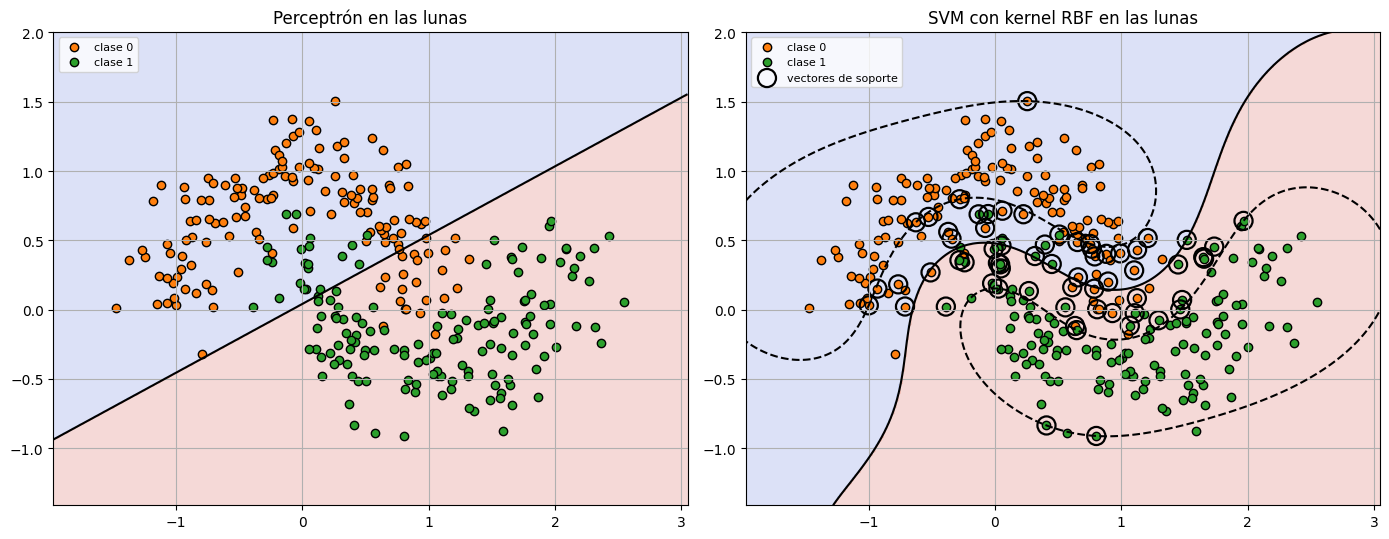

In [23]:
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=42)  # 300 puntos con forma de dos lunas y algo de ruido
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.2, random_state=42, stratify=ym)  # Divide en entrenamiento y prueba

perc_m = make_pipeline(StandardScaler(), Perceptron(eta0=1.0, max_iter=1000, random_state=42))  # Perceptrón para las lunas
svm_m = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))  # SVM con kernel RBF para las lunas
perc_m.fit(Xm_tr, ym_tr)  # Entrena el Perceptrón
svm_m.fit(Xm_tr, ym_tr)  # Entrena la SVM

print(f"Perceptrón     -> exactitud en prueba: {accuracy_score(ym_te, perc_m.predict(Xm_te)):.4f}")  # Resultado del Perceptrón
print(f"SVM (kernel RBF) -> exactitud en prueba: {accuracy_score(ym_te, svm_m.predict(Xm_te)):.4f}")  # Resultado de la SVM

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))  # Crea una figura con 2 gráficas lado a lado
graficar_frontera(ejes[0], perc_m, Xm, ym, "Perceptrón en las lunas", nombres=("clase 0", "clase 1"))  # Frontera del Perceptrón
sv_m = svm_m.named_steps["standardscaler"].inverse_transform(svm_m.named_steps["svc"].support_vectors_)  # Vectores de soporte de la SVM RBF
graficar_frontera(ejes[1], svm_m, Xm, ym, "SVM con kernel RBF en las lunas", nombres=("clase 0", "clase 1"), niveles=(-1, 0, 1), vectores=sv_m)  # Frontera curva de la SVM
plt.tight_layout()  # Acomoda las gráficas sin que se encimen
plt.show()  # Muestra la figura

**Interpretación del experimento B.** El Perceptrón solo puede trazar una **recta** y obtiene alrededor de 0.78 de exactitud en prueba. La SVM con kernel RBF traza una **frontera curva** que sigue la forma de las lunas y llega a alrededor de 0.87. La mejora es real pero moderada, porque con `noise=0.2` las lunas se traslapan y ningún modelo llega a 1.0; lo importante es que la SVM puede **adaptarse a la forma** de los datos y el Perceptrón no. Esta es la diferencia más importante entre ambos: **el truco del kernel**.

## 5. Conclusiones

1. La **SVM** busca el hiperplano de **margen máximo**; solo los **vectores de soporte** determinan la frontera.
2. El hiperparámetro **C** equilibra margen ancho y errores: C pequeño da un margen amplio y tolerante; C grande da un margen estrecho y estricto.
3. Con **kernels** (por ejemplo RBF) la SVM obtiene fronteras **no lineales**, algo que el Perceptrón no puede hacer.
4. Siempre se deben **escalar** las características y elegir los hiperparámetros con **validación cruzada** (`GridSearchCV`), sin usar los datos de prueba.
5. Frente al **Perceptrón**: la SVM da una solución **única y estable** (no depende del orden de los datos), entrega el margen y la distancia a la frontera, y con kernels maneja datos no lineales. En nuestros datos casi lineales **no mejoró la exactitud** de forma apreciable; su ventaja fue de estabilidad e interpretación. A cambio, es más costosa de entrenar con datasets muy grandes.
6. Los datos se importaron desde un **CSV** y pasaron por todo el pipeline: descripción, scatter plot, separación train/test, escalado, entrenamiento, ajuste de hiperparámetros y evaluación.

### Referencias
- scikit-learn, *Support Vector Machines*: https://scikit-learn.org/stable/modules/svm.html
- scikit-learn, *SVC*: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
- scikit-learn, *GridSearchCV*: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Cortes, C. y Vapnik, V. (1995). *Support-vector networks*. Machine Learning, 20(3), 273-297.